# JRA レース予測: 3 着以内に入る確率 (LightGBM + Optuna)

各馬が 3 着以内に入る確率を予測し, ワイド (2 頭とも 3 着以内) の的中確率を計算する.

- 目的変数: `is_top3` / 特徴量: `docs/racing_predict_model_spec.md` 参照 (馬名・オッズ・人気・着順は使わない)
- 検証は時系列 (学習 = 過去, テスト = 直近の開催日のうち全開催日数の `test_ratio` の割合). Optuna もテスト期間を使わずに時系列 CV で探索
- 学習データの期間・テストの比率・Optuna の設定は `configs/train.yaml` で指定する (このノートブックは編集不要)
- 処理の本体は `src/racing_prediction/` (前処理 `features/model_features.py`, 学習 `models/train_model.py`, 推論 `models/predict_model.py`)

## Kaggle で実行する
ローカルで次を実行すると, データ・コードのアップロード → Kaggle でこのノートブックを実行 (Save & Run All)
→ 完了待ち → 学習済みモデルを `models/production/` に取り込む, までを行う (詳細は `docs/github_actions_setup.md`).
```
python scripts/train_on_kaggle.py --update-dataset
```
評価結果 (指標・予測・グラフなど) は `results/` に保存され, スクリプトがローカルの `reports/kaggle_runs/<日時>/` にダウンロードする.
ローカルで実行する場合は準備不要 (`data/processed/races` と `src/` をそのまま使う).


In [12]:
# autoreload はローカルで src/ を編集しながら実行するときだけ使う
# (Kaggle の古い IPython は Python 3.12 で削除された imp を使っていて読み込めないため)
from pathlib import Path

if not Path("/kaggle/input").exists():
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")

import sys
import warnings
from pathlib import Path

import pandas as pd

IS_KAGGLE = Path("/kaggle/input").exists()

def find_kaggle_inputs(input_dir: Path = Path("/kaggle/input"), work_dir: Path = Path("/kaggle/working/inputs")):
    """Kaggle Dataset として追加した src/ (racing_prediction パッケージ) と races/ (CSV) の場所を探す.

    - os.walk(followlinks=True) で探す (Path.rglob は Python 3.12 以前だと
      シンボリックリンクのフォルダの中を "**" で探さないため)
    - src.zip / races.zip のように圧縮ファイルのまま置かれている場合は work_dir に展開して使う
    """
    import os
    import zipfile

    def walk(root: Path):
        for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
            yield Path(dirpath), dirnames, filenames

    def has_csv(root: Path) -> bool:
        return any(name.endswith(".csv") for _, _, filenames in walk(root) for name in filenames)

    # 圧縮ファイルのままの場合は展開する
    for dirpath, _, filenames in walk(input_dir):
        for name in filenames:
            if name.endswith(".zip"):
                dest = work_dir / Path(name).stem
                if not dest.exists():
                    with zipfile.ZipFile(dirpath / name) as zf:
                        zf.extractall(dest)

    src_dir = races_dir = None
    for root in (input_dir, work_dir):
        if not root.exists():
            continue
        for dirpath, dirnames, filenames in walk(root):
            if src_dir is None and dirpath.name == "racing_prediction" and "__init__.py" in filenames:
                src_dir = dirpath.parent
            if races_dir is None and dirpath.name == "races" and has_csv(dirpath):
                races_dir = dirpath

    if src_dir is None or races_dir is None:
        listing = "\n".join(
            f"  {p.relative_to(input_dir)}{'/' if p.is_dir() else ''}"
            for p in sorted(input_dir.glob("*/*"))[:50]
        ) or "  (空です. データセットが 1 つも追加されていません)"
        missing = [name for name, d in [("src/racing_prediction (学習コード)", src_dir), ("races/ (CSV)", races_dir)] if d is None]
        raise FileNotFoundError(
            f"/kaggle/input に {', '.join(missing)} が見つかりません.\n"
            f"/kaggle/input の中身:\n{listing}\n\n"
            "対処法:\n"
            "  1. ローカルで python scripts/prepare_kaggle_dataset.py --kaggle-user <ユーザー名> を実行\n"
            "  2. kaggle datasets create -p build/kaggle_dataset --dir-mode zip でアップロード (2 回目以降は version)\n"
            "  3. このノートブックの右側の「Add Input」(Input > + Add Input) で racing-prediction-data を追加\n"
            "     (データセットを更新したら, Input の該当データセットの「⋮ > Check for updates」で最新版にする)"
        )
    return src_dir, races_dir


def check_dataset_fingerprint(expected: str | None, input_dir: Path = Path("/kaggle/input")) -> None:
    """使われているデータセットが, アップロードした最新版かを識別値 (dataset_fingerprint.txt) で確かめる.

    Kaggle はデータセットを更新した直後だと前の版でノートブックを実行することがあり,
    そのまま進むと古いコード・設定 (configs/train.yaml)・データで学習してしまうため, ここで止める.
    """
    import os

    found = None
    for dirpath, _, filenames in os.walk(input_dir, followlinks=True):
        if "dataset_fingerprint.txt" in filenames:
            found = (Path(dirpath) / "dataset_fingerprint.txt").read_text(encoding="utf-8").strip()
            break
    print("データセットの識別値:", found, "| 期待する識別値:", expected)
    if expected is None:  # Kaggle の画面から手動で実行した場合は確認しない
        return
    if found != expected:
        raise RuntimeError(
            f"使われているデータセット (識別値 {found}) が, アップロードした最新版 (識別値 {expected}) ではありません. "
            "Kaggle への反映が間に合っていない可能性があります. 数分おいてから "
            "`python scripts/train_on_kaggle.py` を再実行してください."
        )


# scripts/train_on_kaggle.py で実行すると, アップロードしたデータセットの識別値がここに埋め込まれる
EXPECTED_DATASET_FINGERPRINT = None

if IS_KAGGLE:
    SRC_DIR, RACES_DIR = find_kaggle_inputs()
    check_dataset_fingerprint(EXPECTED_DATASET_FINGERPRINT)
    ARTIFACTS_DIR = Path("/kaggle/working/artifacts")
    RESULTS_DIR = Path("/kaggle/working/results")   # 評価結果 (scripts/train_on_kaggle.py がローカルに保存する)
else:
    ROOT = Path.cwd().parent
    SRC_DIR = ROOT / "src"
    RACES_DIR = ROOT / "data" / "processed" / "races"
    ARTIFACTS_DIR = ROOT / "models" / "latest"
    RESULTS_DIR = ROOT / "reports" / "latest"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

# グラフで日本語を表示するフォント (Kaggle ではデータセットに同梱した assets/fonts/ の Noto Sans JP を使う).
# 見つからなければ None になり, グラフは英語で描く (文字化けさせないため)
from racing_prediction.visualization.visualize import setup_japanese_font

JAPANESE_FONT = setup_japanese_font([SRC_DIR.parent / "assets" / "fonts"])
print("グラフの日本語フォント:", JAPANESE_FONT or "なし (グラフは英語で表示)")

import optuna

from racing_prediction.features.model_features import load_race_csvs, labeled
from racing_prediction.models.train_model import (
    evaluate,
    filter_period,
    save_artifacts,
    time_split,
    train_final,
    tune,
)
from racing_prediction.models.predict_model import (
    calibration_table,
    feature_importance,
    roc_auc_summary,
    load_artifacts,
    predict_top3,
    wide_probabilities,
)

pd.set_option("display.max_columns", 50)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---- 設定 (configs/train.yaml から読み込む) ----
from racing_prediction.config import load_train_config

CONFIG_PATH = SRC_DIR.parent / "configs" / "train.yaml"   # Kaggle ではデータセット内の configs/train.yaml
cfg = load_train_config(CONFIG_PATH)

DATA_START_DATE = cfg.start_date   # 学習・テストに使うデータの開始日 (None なら制限なし)
DATA_END_DATE = cfg.end_date       # 学習・テストに使うデータの終了日 (None なら制限なし)
TEST_RATIO = cfg.test_ratio        # 全開催日数のうち, 直近の何割の開催日をテストにするか
N_TRIALS = cfg.n_trials            # Optuna の試行回数
TIMEOUT = cfg.timeout_sec          # Optuna の打ち切り時間 (秒)
N_FOLDS = cfg.n_folds              # 時系列 CV の fold 数

print("設定:", CONFIG_PATH)
for key, value in cfg.to_dict().items():
    print(f"  {key}: {value}")

print("Kaggle" if IS_KAGGLE else "ローカル", "| src:", SRC_DIR, "| races:", RACES_DIR)

## 1. データの読み込み
結果が確定したレース (`is_top3` がある行) のうち, `configs/train.yaml` の `data.start_date` 〜 `data.end_date` の期間のものを学習・評価に使う.

In [13]:
df_all = load_race_csvs(RACES_DIR)
df = filter_period(labeled(df_all), DATA_START_DATE, DATA_END_DATE)

print(f"{df['race_id'].nunique()} レース / {len(df)} 頭 / {df['race_date'].nunique()} 開催日  ({df['race_date'].min().date()} 〜 {df['race_date'].max().date()})")
print("3着以内の割合:", round(df["is_top3"].mean(), 3))
display(df.groupby(["race_venue", "race_surface"])["race_id"].nunique().rename("レース数").to_frame())

48 レース / 671 頭 / 9 開催日  (2025-11-23 〜 2026-02-14)
3着以内の割合: 0.215


レース数
race_venue race_surface      
東京         dirt            20
           turf            28

In [14]:
# 平均着順の欠損率 (出走経験がない条件は NaN. LightGBM は NaN をそのまま扱える)
avg_cols = [c for c in df.columns if c.startswith("avg_rank_")]
df[avg_cols].isna().mean().sort_values().rename("欠損率").to_frame().T

,avg_rank_turf,avg_rank_turf_good,avg_rank_turf_mid,avg_rank_dirt,avg_rank_dirt_good,avg_rank_turf_tokyo,avg_rank_dirt_mid,avg_rank_dirt_yielding,avg_rank_turf_nakayama,avg_rank_dirt_tokyo,avg_rank_turf_yielding,avg_rank_dirt_short,avg_rank_dirt_nakayama,avg_rank_turf_niigata,avg_rank_dirt_soft,avg_rank_turf_short,avg_rank_turf_chukyo,avg_rank_turf_kyoto,avg_rank_dirt_chukyo,avg_rank_turf_hanshin,avg_rank_turf_fukushima,avg_rank_dirt_heavy,avg_rank_dirt_niigata,avg_rank_turf_soft,avg_rank_dirt_hanshin,avg_rank_dirt_kyoto,avg_rank_dirt_fukushima,avg_rank_turf_sapporo,avg_rank_turf_hakodate,avg_rank_turf_kokura,avg_rank_turf_long,avg_rank_dirt_sapporo,avg_rank_dirt_kokura,avg_rank_dirt_hakodate,avg_rank_turf_heavy,avg_rank_turf_overseas,avg_rank_dirt_long,avg_rank_dirt_overseas
欠損率,0.250373,0.281669,0.317437,0.432191,0.467958,0.47839,0.532042,0.564829,0.5693,0.5693,0.585693,0.628912,0.66617,0.679583,0.681073,0.722802,0.751118,0.754098,0.755589,0.757079,0.782414,0.791356,0.792846,0.821162,0.821162,0.821162,0.830104,0.843517,0.891207,0.891207,0.918033,0.922504,0.937407,0.949329,0.9538,0.985097,0.991058,0.994039


## 2. 時系列での分割
開催日を新しい順に並べ, 全開催日数の `split.test_ratio` (`configs/train.yaml`) の割合をテスト (チューニングにも使わない), それより前を学習にする.
カレンダーの月数ではなく開催日の数で分けるので, 開催がない月があってもテストの量が安定する.

In [15]:
train, test = time_split(df, test_ratio=TEST_RATIO)
for name, d in [("学習", train), ("テスト", test)]:
    print(f"{name}: {d['race_date'].min().date()} 〜 {d['race_date'].max().date()}  {d['race_date'].nunique()} 開催日 / {d['race_id'].nunique()} レース / {len(d)} 頭")

学習: 2025-11-23 〜 2026-02-07  7 開催日 / 37 レース / 524 頭
テスト: 2026-02-10 〜 2026-02-14  2 開催日 / 11 レース / 147 頭


## 3. Optuna によるハイパーパラメータ探索
学習期間内で期間をずらした時系列 CV (`tuning.n_folds` fold. 試行回数・打ち切り時間も `configs/train.yaml` の `tuning`) の平均 logloss を最小化する.

In [16]:
result = tune(train, n_trials=N_TRIALS, timeout=TIMEOUT, n_folds=N_FOLDS)

print("CV logloss:", round(result.best_score, 4))
print("木の本数:", result.num_boost_round)
result.best_params

  0%|          | 0/100 [00:00<?, ?it/s]

CV logloss: 0.4559
木の本数: 43


{'objective': 'binary',
 'metric': 'binary_logloss',
 'learning_rate': 0.05,
 'bagging_freq': 1,
 'verbosity': -1,
 'seed': 42,
 'deterministic': True,
 'force_col_wise': True,
 'num_leaves': 53,
 'min_child_samples': 10,
 'feature_fraction': 0.978936896513396,
 'bagging_fraction': 0.9162213204002109,
 'lambda_l1': 0.0070689749506246055,
 'lambda_l2': 0.005337032762603957,
 'min_data_per_group': 17,
 'cat_smooth': 4.059611610484305,
 'min_category_count': 9}

In [17]:
# どのハイパーパラメータが効いたか (試行が少ないと不安定)
try:
    display(pd.Series(optuna.importance.get_param_importances(result.study)).rename("重要度").to_frame())
except Exception as e:
    print("重要度を計算できませんでした:", e)

,重要度
cat_smooth,0.566799
lambda_l2,0.121191
min_category_count,0.106477
num_leaves,0.070834
min_data_per_group,0.053410
min_child_samples,0.031620
feature_fraction,0.022966
bagging_fraction,0.013776
lambda_l1,0.012927


## 4. 学習期間全体で学習し, テスト期間で評価
- `logloss` / `brier`: 確率としての正確さ (`p_top3` はレース内の合計を 3 に補正した確率. `_raw` は補正前)
- `roc_auc`: ROC-AUC. 3 着以内の馬をどれだけ上位に並べられたか (0.5 = ランダム, 1.0 = 完璧)
- `roc_auc_by_race`: レースごとの ROC-AUC の平均 (同じレース内での順番付けの良さ. ワイドの予想に直結)
- `top3_precision`: 予測上位 3 頭のうち実際に 3 着以内だった割合
- `wide_top_pair_hit`: 予測上位 2 頭のワイドが的中したレースの割合

In [18]:
builder, booster = train_final(train, result.best_params, result.num_boost_round)
metrics, pred_test = evaluate(booster, builder, test)

# 参考: 人気順 (確定オッズ) で予想した場合 (モデルの特徴量には使っていない. 比較用)
fav = test.assign(pred_rank=test["popularity"], odds_score=1 / test["win_odds"])
baseline = {
    **roc_auc_summary(fav, "odds_score"),
    "top3_precision": fav[fav["pred_rank"] <= 3].groupby("race_id")["is_top3"].sum().div(3).mean(),
    "wide_top_pair_hit": (fav[fav["pred_rank"] <= 2].groupby("race_id")["is_top3"].sum() == 2).mean(),
}

display(pd.DataFrame({"モデル": pd.Series(metrics), "参考: 人気順": pd.Series(baseline)}))
print(f"ROC-AUC: モデル {metrics['roc_auc']:.4f} (レース内平均 {metrics['roc_auc_by_race']:.4f}) "
      f"/ 人気順 {baseline['roc_auc']:.4f} (レース内平均 {baseline['roc_auc_by_race']:.4f})")

,モデル,参考: 人気順
brier,0.157031,NaN
logloss,0.475595,NaN
logloss_raw,0.502117,NaN
n_races,11.000000,NaN
n_rows,147.000000,NaN
roc_auc,0.724083,0.810606
roc_auc_by_race,0.711500,0.809635
roc_auc_raw,0.716906,NaN
top3_precision,0.393939,0.515152
wide_top_pair_hit,0.272727,0.272727


ROC-AUC: モデル 0.7241 (レース内平均 0.7115) / 人気順 0.8106 (レース内平均 0.8096)


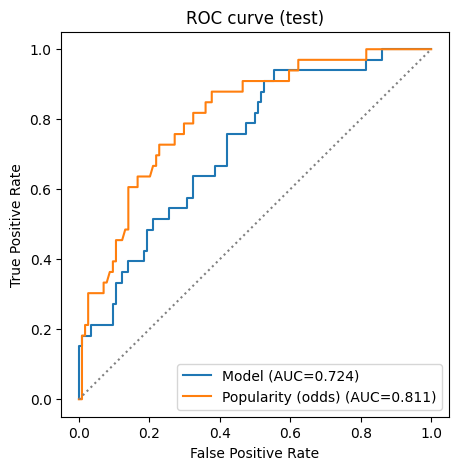

In [19]:
# ROC 曲線 (左上に近いほど良い. 点線はランダム). Kaggle は日本語フォントがないため図中の文字は英語
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5, 5))
for label, data, col in [("Model", pred_test, "p_top3"), ("Popularity (odds)", fav, "odds_score")]:
    d = data.dropna(subset=[col])
    fpr, tpr, _ = roc_curve(d["is_top3"].astype(int), d[col])
    auc = roc_auc_summary(d, col)["roc_auc"]
    ax.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle=":", color="gray")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curve (test)")
ax.legend()
fig.savefig(RESULTS_DIR / "roc_curve.png", dpi=120, bbox_inches="tight")
plt.show()


In [20]:
# 予測確率と実際の 3 着以内率のずれ (mean_pred と actual_rate が近いほど良い)
calibration_table(pred_test)

,p_top3_bin,n,mean_pred,actual_rate
0,"(-0.001, 0.1]",56,0.054154,0.053571
1,"(0.1, 0.2]",31,0.152974,0.290323
2,"(0.2, 0.3]",23,0.241349,0.260870
3,"(0.3, 0.4]",12,0.341966,0.333333
4,"(0.4, 0.5]",9,0.445526,0.444444
5,"(0.5, 0.6]",4,0.543333,0.000000
6,"(0.6, 0.7]",6,0.666332,0.333333
7,"(0.7, 0.8]",1,0.710432,0.000000
8,"(0.8, 0.9]",2,0.847020,1.000000
9,"(0.9, 1.0]",3,0.995000,1.000000


### 特徴量の重要度
- `feature_ja`: 特徴量の日本語名 (`feature` は英語名)
  - 「今回の○○での平均着順」: 今回のレース条件 (芝・ダート / 距離 / 馬場状態 / 競馬場) と同じ条件での過去の平均着順
  - 「(補正後)」: 出走回数が少ないほど全体の平均着順に寄せた値 (1〜2 戦だけの成績でぶれないようにしたもの)
  - 「レース内順位」: 同じレースの出走馬の中での順位 (0〜1. 小さいほど上位) / 「レース内平均との差」: 同じレースの平均との差
- `gain`: その特徴量で分岐したときの損失の減少量の合計 (LightGBM 標準). `gain_share` は全体に占める割合
- `split`: 分岐に使われた回数 (多くても gain が小さければ効いていない)
- `shap`: テスト期間での SHAP 値の絶対値の平均. 予測を実際にどれだけ動かしたか (gain より解釈しやすい)

`IMPORTANCE_SORT_BY` で並び順の基準を選べる. 全特徴量を重要度の高い順に表示する.

In [21]:
IMPORTANCE_SORT_BY = "shap"   # "shap" / "gain" / "split"

importance = feature_importance(booster, builder, test, sort_by=IMPORTANCE_SORT_BY)

with pd.option_context("display.max_rows", None):
    try:  # 棒付きの表 (jinja2 が必要. なければ普通の表で表示)
        display(importance.style.format({"gain": "{:.1f}", "gain_share": "{:.2%}", "shap": "{:.4f}"}).bar(subset=[IMPORTANCE_SORT_BY], color="#8ecae6"))
    except ImportError:
        display(importance)

,feature,gain,gain_share,split,shap
rank,,,,,
1,shr_avg_rank_surface_race_diff,474.3,12.10%,47,0.4194
2,jockey_name,167.8,4.28%,30,0.2298
3,cur_avg_rank_surface,229.5,5.85%,32,0.1807
4,shr_avg_rank_surface_race_rank,135.8,3.46%,37,0.1462
5,avg_rank_turf,127.6,3.26%,25,0.0940
6,avg_rank_turf_tokyo,77.7,1.98%,25,0.0752
7,age_race_diff,93.9,2.39%,18,0.0733
8,shr_avg_rank_venue_race_diff,85.7,2.19%,28,0.0730
9,waku,89.1,2.27%,26,0.0714


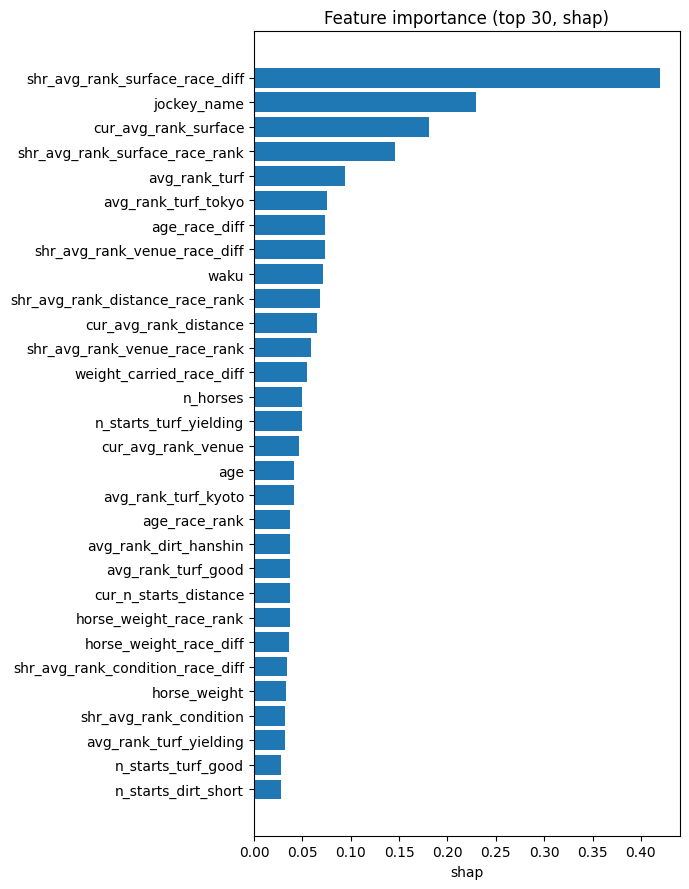

分岐に使われなかった特徴量: 33 / 122 ['avg_rank_turf_heavy', 'n_starts_turf_fukushima', 'n_starts_turf_niigata', 'n_starts_turf_heavy', 'n_starts_turf_hakodate', 'n_starts_turf_soft', 'n_starts_turf_long', 'avg_rank_dirt_overseas', 'avg_rank_dirt_fukushima', 'avg_rank_dirt_hakodate', 'avg_rank_dirt_long', 'avg_rank_turf_hakodate', 'avg_rank_turf_overseas', 'n_starts_turf_overseas', 'n_starts_turf_chukyo', 'n_starts_turf_hanshin', 'n_starts_dirt_fukushima', 'n_starts_dirt_kokura', 'n_starts_dirt_niigata', 'n_starts_dirt_overseas', 'n_starts_turf_kokura', 'n_starts_dirt_long', 'n_starts_dirt_heavy', 'n_starts_dirt_hakodate', 'race_venue', 'race_surface', 'race_track_condition', 'sire_line', 'trainer_name', 'dam', 'sire_sire', 'dam_sire', 'dam_dam']


In [22]:
# 上位 30 特徴量の棒グラフ (重要度の高いものが上).
# 日本語フォントがあれば日本語名, なければ英語名で描く (フォントがない環境で日本語を描くと □ に文字化けするため)
SORT_LABEL_JA = {"shap": "SHAP 値の絶対値の平均", "gain": "gain (損失の減少量の合計)", "split": "分岐に使われた回数"}
top = importance.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 9))
if JAPANESE_FONT:
    ax.barh(top["feature_ja"], top[IMPORTANCE_SORT_BY])
    ax.set_xlabel(SORT_LABEL_JA.get(IMPORTANCE_SORT_BY, IMPORTANCE_SORT_BY))
    ax.set_title(f"特徴量の重要度 (上位 30, テスト期間)")
else:
    ax.barh(top["feature"], top[IMPORTANCE_SORT_BY])
    ax.set_xlabel(IMPORTANCE_SORT_BY)
    ax.set_title(f"Feature importance (top 30, {IMPORTANCE_SORT_BY})")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "feature_importance_top30.png", dpi=120, bbox_inches="tight")
plt.show()

# 使われていない特徴量 (分岐に一度も使われなかったもの)
unused = importance.loc[importance["split"] == 0, "feature_ja"].tolist()
print(f"分岐に使われなかった特徴量: {len(unused)} / {len(importance)}")
print("  " + " / ".join(unused))

### 評価結果の保存
評価結果をファイルに保存する (Kaggle では `/kaggle/working/results/`, ローカルでは `reports/latest/`).
`scripts/train_on_kaggle.py` で実行した場合は, ローカルの `reports/kaggle_runs/<日時>/results/` にダウンロードされる.

| ファイル | 内容 |
|---|---|
| `summary.json` | 設定, 学習・テスト期間, CV / テストの評価指標 (モデルと人気順), 最良パラメータ |
| `test_predictions.csv` | テスト期間の各馬の予測確率と結果 |
| `calibration.csv` | 予測確率帯ごとの実際の 3 着以内率 |
| `feature_importance_test.csv` | 特徴量の重要度 (gain / split / SHAP) |
| `optuna_trials.csv` | Optuna の全試行のパラメータとスコア |
| `roc_curve.png` / `feature_importance_top30.png` | グラフ |

In [ ]:
import json


def _to_builtin(o):
    """numpy の数値などを JSON に書ける形にする."""
    return o.item() if hasattr(o, "item") else str(o)


summary = {
    "config": cfg.to_dict(),
    "data_period": [str(df["race_date"].min().date()), str(df["race_date"].max().date())],
    "train_period": [str(train["race_date"].min().date()), str(train["race_date"].max().date())],
    "test_period": [str(test["race_date"].min().date()), str(test["race_date"].max().date())],
    "n_races": {"train": int(train["race_id"].nunique()), "test": int(test["race_id"].nunique())},
    "cv_logloss": result.best_score,
    "num_boost_round": result.num_boost_round,
    "best_params": result.best_params,
    "test_metrics": {"model": metrics, "popularity_baseline": baseline},
    "n_unused_features": len(unused),
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=_to_builtin), encoding="utf-8")

prediction_cols = [
    "race_id", "race_date", "race_venue", "umaban", "horse_name",
    "p_top3_raw", "p_top3", "pred_rank", "rank", "is_top3", "popularity", "win_odds",
]
pred_test[prediction_cols].to_csv(RESULTS_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")
calibration_table(pred_test).astype({"p_top3_bin": str}).to_csv(RESULTS_DIR / "calibration.csv", index=False, encoding="utf-8-sig")
importance.to_csv(RESULTS_DIR / "feature_importance_test.csv", encoding="utf-8-sig")
result.study.trials_dataframe().to_csv(RESULTS_DIR / "optuna_trials.csv", index=False, encoding="utf-8-sig")

print("評価結果を保存しました:", RESULTS_DIR)
for p in sorted(RESULTS_DIR.iterdir()):
    print(f"  {p.name} ({p.stat().st_size:,} bytes)")

## 5. 全期間で学習し直して保存
テストで性能を確認したら, テスト期間も含めた全期間 (`data.start_date` 〜 `data.end_date`) で学習し直したモデルを推論用に保存する.
Kaggle では `/kaggle/working/artifacts` に保存される (ノートブックの Output からダウンロードできる).

In [24]:
builder_full, booster_full = train_final(df, result.best_params, result.num_boost_round)
save_artifacts(
    ARTIFACTS_DIR,
    booster_full,
    builder_full,
    result.best_params,
    result.num_boost_round,
    train=df,
    metrics={
        "test": metrics,
        "cv_logloss": result.best_score,
        "test_ratio": TEST_RATIO,
        "config": cfg.to_dict(),
        "test_period": [str(test["race_date"].min().date()), str(test["race_date"].max().date())],
    },
)
feature_importance(booster_full, builder_full, df).to_csv(ARTIFACTS_DIR / "feature_importance.csv", encoding="utf-8-sig")
print("保存しました:", ARTIFACTS_DIR, [p.name for p in ARTIFACTS_DIR.iterdir()])

保存しました: /kaggle/working/artifacts ['metadata.json', 'model.txt', 'feature_importance.csv']


## 6. 推論
保存したモデルを読み込み, レースごとに 3 着以内の確率とワイドの確率を出す (テスト期間のレースで例示).

In [23]:
booster_loaded, builder_loaded, metadata = load_artifacts(ARTIFACTS_DIR)

race_id = test["race_id"].iloc[-1]   # 予測したいレース
race = predict_top3(test[test["race_id"] == race_id], booster_loaded, builder_loaded).sort_values("pred_rank")
display(race[["umaban", "horse_name", "p_top3", "pred_rank", "rank", "popularity", "win_odds"]])

# ワイドの的中確率 (上位 10 組)
wide_probabilities(race).head(10)

[LightGBM] [Fatal] Could not open /kaggle/working/artifacts/model.txt


LightGBMError: Could not open /kaggle/working/artifacts/model.txt

### これから行われるレースを予測する (任意)
netkeiba から出馬表・戦績・血統を取得して予測する. 馬体重の発表 (発走 60 分前) 後に実行する.
Kaggle で実行する場合はノートブックの設定で **Internet を ON** にする. 1 レースあたり 1〜2 分かかる.

In [ ]:
from racing_prediction.data.make_dataset import build_race_table

UPCOMING_RACE_ID = None   # 例: "202605050611"

if UPCOMING_RACE_ID:
    upcoming = build_race_table(UPCOMING_RACE_ID)
    upcoming_pred = predict_top3(upcoming, booster_loaded, builder_loaded).sort_values("pred_rank")
    display(upcoming_pred[["umaban", "horse_name", "horse_weight", "weight_diff", "p_top3", "pred_rank"]])
    display(wide_probabilities(upcoming_pred).head(10))